# nctoolkit vs PyFVCOM on real FVCOM output

Does nctoolkit give essentially the same answers as [PyFVCOM](https://github.com/PlymouthMarineLaboratory/pyfvcom)
for the vertical and horizontal grid methods?

* **Data:** `aqua_v16_trawl_avg_0001_2012_01.nc` (39,318 nodes, 75,473 elements, 24 sigma layers). First 3 days.
* **Variable:** `temp` (on nodes, 3D, no missing values) for most methods, and `u` for the element grid.
* **Reference:** PyFVCOM reads the file, and supplies the depths (`unstructured_grid_depths`), element areas and FVCOM's own control-volume areas (`art1`). Where PyFVCOM has no function (thickness weighting, interpolation to depths, regridding) the reference is numpy/matplotlib on PyFVCOM's grid.
  The reference code is in `tests/pyfvcom_reference.py`, and the same checks are in `tests/test_fvcom_pyfvcom.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "tests")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nctoolkit as nc
from pyfvcom_reference import FVCOM, NTIME, Reference, compare, import_pyfvcom

nc.options(lazy=True, progress=False) if "progress" in nc.options.__code__.co_varnames else nc.options(lazy=True)
PyFVCOM, _, _ = import_pyfvcom()
print("PyFVCOM", PyFVCOM.__version__, "| nctoolkit", nc.__version__ if hasattr(nc, "__version__") else "")

ds = nc.open_fvcom(FVCOM, ["temp", "zeta"]); ds.subset(time=range(NTIME)); ds.run()
dse = nc.open_fvcom(FVCOM, "u"); dse.subset(time=range(NTIME)); dse.run()
ref, eref = Reference("temp"), Reference("u", "element")
print(ds.variables, dse.variables)

2 temporary files were created by nctoolkit in prior or current sessions. Consider running deep_clean!


nctoolkit is using Climate Data Operators version 2.4.1


PyFVCOM 2.2.0 | nctoolkit 1.4.0


['layer_thickness', 'temp', 'zeta'] ['layer_thickness', 'u']


In [2]:
results = []

def values(d, var):
    d = d.copy(); d.run()
    return d.to_xarray()[var].values

def record(method, got, expected, tol, note=""):
    abs_diff, rel_diff, only_one = compare(got, expected)
    ok = rel_diff <= tol and only_one == 0
    results.append(dict(method=method, max_abs_diff=abs_diff, max_rel_diff=rel_diff,
                        missing_in_one_only=only_one, tolerance=tol, agrees=ok, note=note))
    print(f"{'OK  ' if ok else 'FAIL'} {method:38s} abs {abs_diff:.2e}  rel {rel_diff:.2e}  one-sided missing {only_one}")

def apply(d, method, *args, pre=(), **kwargs):
    d = d.copy()
    for p in pre: getattr(d, p)()
    getattr(d, method)(*args, **kwargs)
    return d

## Vertical grid

Layer thickness is the basis of nctoolkit's vertical weighting: `(siglev[k] - siglev[k+1]) * (h + zeta)`.

In [3]:
record("layer_thickness (nodes)", values(ds, "layer_thickness"), ref.thickness, 1e-6)
record("layer_thickness (elements)", values(dse, "layer_thickness"), eref.thickness, 1e-6)

OK   layer_thickness (nodes)                abs 4.77e-07  rel 3.40e-08  one-sided missing 0
OK   layer_thickness (elements)             abs 4.77e-07  rel 3.64e-08  one-sided missing 0


### Depth averages and integrals (thickness weighted)

In [4]:
record("vertical_mean", values(apply(ds, "vertical_mean"), "temp"), ref.vertical_mean(), 1e-6)
record("vertical_mean (elements)", values(apply(dse, "vertical_mean"), "u"), eref.vertical_mean(), 1e-6)
record("vertical_integration", values(apply(ds, "vertical_integration"), "temp"), ref.vertical_integration(), 1e-6)
record("vertical_mean(depth_range=[0,20])", values(apply(ds, "vertical_mean", depth_range=[0, 20]), "temp"), ref.vertical_mean(0, 20), 1e-6,
       "layers partly inside the range are weighted by the overlap")
record("vertical_integration(depth_range=[0,20])", values(apply(ds, "vertical_integration", depth_range=[0, 20]), "temp"), ref.vertical_integration(0, 20), 1e-6)

OK   vertical_mean                          abs 4.85e-07  rel 3.36e-08  one-sided missing 0


OK   vertical_mean (elements)               abs 5.67e-08  rel 4.97e-08  one-sided missing 0


OK   vertical_integration                   abs 1.70e-04  rel 6.25e-08  one-sided missing 0


OK   vertical_mean(depth_range=[0,20])      abs 2.02e-06  rel 1.40e-07  one-sided missing 0


OK   vertical_integration(depth_range=[0,20]) abs 3.43e-05  rel 1.19e-07  one-sided missing 0


### Layer selection and unweighted statistics across layers

In [5]:
record("top", values(apply(ds, "top"), "temp"), ref.values[:, 0], 1e-6)
record("bottom", values(apply(ds, "bottom"), "temp"), ref.values[:, -1], 1e-6)
for m, f in [("vertical_min", lambda x: x.min(1)), ("vertical_max", lambda x: x.max(1)),
             ("vertical_range", lambda x: np.ptp(x, axis=1)), ("vertical_sum", lambda x: x.sum(1)),
             ("vertical_cumsum", lambda x: np.cumsum(x, axis=1))]:
    record(m, values(apply(ds, m), "temp"), f(ref.values), 1e-6, "not thickness weighted")

OK   top                                    abs 0.00e+00  rel 0.00e+00  one-sided missing 0


OK   bottom                                 abs 0.00e+00  rel 0.00e+00  one-sided missing 0


OK   vertical_min                           abs 0.00e+00  rel 0.00e+00  one-sided missing 0


OK   vertical_max                           abs 0.00e+00  rel 0.00e+00  one-sided missing 0
OK   vertical_range                         abs 0.00e+00  rel 0.00e+00  one-sided missing 0


OK   vertical_sum                           abs 1.53e-05  rel 4.40e-08  one-sided missing 0


OK   vertical_cumsum                        abs 1.53e-05  rel 4.40e-08  one-sided missing 0


### Surface and bottom masks

Both should flag one level only: layer 1 for the surface, layer 24 for the bottom.

In [6]:
for m, layer in [("surface_mask", 0), ("bottom_mask", -1)]:
    d = ds.copy(); d.subset(variables="temp", time=0); getattr(d, m)()
    mask = d.to_xarray().bottom.values.reshape(24, -1)
    expected = np.full_like(mask, np.nan); expected[layer] = 1
    record(m, mask, expected, 0)

OK   surface_mask                           abs 0.00e+00  rel 0.00e+00  one-sided missing 0


OK   bottom_mask                            abs 0.00e+00  rel 0.00e+00  one-sided missing 0


### Interpolation to fixed depths (`vertical_interp`, `to_zlevels`)

OK   vertical_interp([5,10,50])             abs 6.01e-07  rel 4.16e-08  one-sided missing 0
OK   to_zlevels == vertical_interp          abs 0.00e+00  rel 0.00e+00  one-sided missing 0


<Figure size 400x400 with 0 Axes>

Text(0.5, 0, 'temp')

Text(0, 0.5, 'depth below surface (m)')

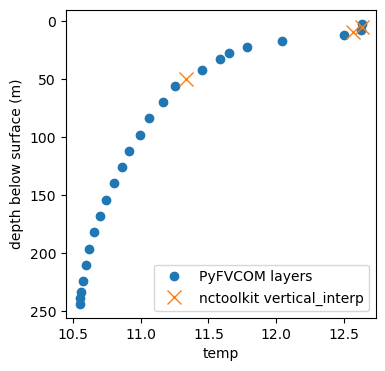

In [7]:
levels = [5, 10, 50]
interp = values(apply(ds, "vertical_interp", levels), "temp")
record("vertical_interp([5,10,50])", interp, ref.at_depths(levels), 1e-6,
       "linear between layer centres; end values held; missing below the seabed")
d = ds.copy(); d.to_zlevels(levels=[5, 10]); e = apply(ds, "vertical_interp", [5, 10])
record("to_zlevels == vertical_interp", values(d, "temp"), values(e, "temp"), 0)

# the profile at the deepest node
j = int(np.argmax(ref.h)); t = 0
plt.figure(figsize=(4, 4))
plt.plot(ref.values[t, :, j], ref.centre_depth[t, :, j], "o", label="PyFVCOM layers")
plt.plot(interp[t, :, j], levels, "x", ms=10, label="nctoolkit vertical_interp")
plt.gca().invert_yaxis(); plt.xlabel("temp"); plt.ylabel("depth below surface (m)"); plt.legend(); plt.show()

## Horizontal grid

### Cell areas

In [8]:
d = ds.copy(); d.cell_area(join=False)
areas = d.to_xarray().cell_area.values.ravel()
ratio = areas / ref.area
print("nodes: nctoolkit / FVCOM art1 =", ratio.min().round(4), "-", ratio.max().round(4))
record("cell_area (nodes) vs art1", areas, ref.area, 1e-2, "art1 is in projected metres, nctoolkit's areas are on the sphere")
d = dse.copy(); d.cell_area(join=False)
areas_e = d.to_xarray().cell_area.values.ravel()
print("elements: nctoolkit / triangle area =", (areas_e / eref.area).min().round(4), "-", (areas_e / eref.area).max().round(4))
record("cell_area (elements) vs triangles", areas_e, eref.area, 1.5e-2, "as above")

nodes: nctoolkit / FVCOM art1 = 0.9916 - 0.998
OK   cell_area (nodes) vs art1              abs 8.11e+05  rel 7.50e-03  one-sided missing 0
elements: nctoolkit / triangle area = 0.9918 - 0.9979
OK   cell_area (elements) vs triangles      abs 3.74e+05  rel 7.09e-03  one-sided missing 0


### Spatial statistics

All are on the surface layer. `spatial_mean` is area weighted by control volume.

In [9]:
x, w = ref.values[:, 0], ref.area
top = apply(ds, "top")
mean = (x * w).sum(-1) / w.sum()
record("spatial_mean", values(apply(top, "spatial_mean"), "temp"), mean, 2e-4, "sphere vs projected areas")
xe = eref.values[:, 0]
record("spatial_mean (elements)", values(apply(dse, "spatial_mean", pre=["top"]), "u"), (xe * eref.area).sum(-1) / eref.area.sum(), 5e-4, "sphere vs projected areas")
record("spatial_max", values(apply(top, "spatial_max"), "temp"), x.max(-1), 1e-6)
record("spatial_min", values(apply(top, "spatial_min"), "temp"), x.min(-1), 1e-6)
record("spatial_range", values(apply(top, "spatial_range"), "temp"), np.ptp(x, axis=-1), 1e-6)
record("spatial_sum", values(apply(top, "spatial_sum"), "temp"), x.sum(-1), 1e-6, "by_area=False: plain sum")
wn = w / w.sum()
record("spatial_stdev", values(apply(top, "spatial_stdev"), "temp"), np.sqrt((((x - mean[:, None]) ** 2) * wn).sum(-1)), 1e-3, "area weighted")
record("spatial_percentile(p=50)", values(apply(top, "spatial_percentile", p=50), "temp"), np.median(x, axis=-1), 1e-4, "not area weighted")

OK   spatial_mean                           abs 7.45e-04  rel 6.61e-05  one-sided missing 0
OK   spatial_mean (elements)                abs 1.65e-05  rel 1.42e-04  one-sided missing 0


OK   spatial_max                            abs 0.00e+00  rel 0.00e+00  one-sided missing 0
OK   spatial_min                            abs 0.00e+00  rel 0.00e+00  one-sided missing 0
OK   spatial_range                          abs 4.77e-07  rel 5.27e-08  one-sided missing 0


OK   spatial_sum                            abs 3.25e-03  rel 7.52e-09  one-sided missing 0
OK   spatial_stdev                          abs 4.07e-04  rel 3.09e-04  one-sided missing 0


OK   spatial_percentile(p=50)               abs 1.31e-04  rel 1.18e-05  one-sided missing 0


### Centre

In [10]:
one = apply(ds, "top"); one.subset(variables="temp")
record("centre('latitude')", values(apply(one, "centre", "latitude"), "temp"), (ref.lat * x).sum(-1) / x.sum(-1), 1e-6)
wx = x * ref.area
record("centre('longitude', by_area=True)", values(apply(one, "centre", "longitude", by_area=True), "temp"), (ref.lon * wx).sum(-1) / wx.sum(-1), 1e-3)

OK   centre('latitude')                     abs 1.42e-06  rel 2.69e-08  one-sided missing 0


OK   centre('longitude', by_area=True)      abs 2.25e-03  rel 3.58e-04  one-sided missing 0


### Selecting a region

In [11]:
box = dict(lon=[-6, -4], lat=[50, 51])
inside = (ref.lon >= -6) & (ref.lon <= -4) & (ref.lat >= 50) & (ref.lat <= 51)
c = values(apply(top, "crop", **box), "temp")[0].ravel()
print("nodes in box:", inside.sum(), "| nctoolkit crop:", c.size)
record("crop", np.sort(c), np.sort(x[0][inside]), 0)
m = values(apply(top, "mask_box", **box), "temp")[0].ravel()
record("mask_box (values)", m[inside], x[0][inside], 0)
record("mask_box (which nodes kept)", np.isfinite(m).astype(float), inside.astype(float), 0)

nodes in box: 1879 | nctoolkit crop: 1879
OK   crop                                   abs 0.00e+00  rel 0.00e+00  one-sided missing 0


OK   mask_box (values)                      abs 0.00e+00  rel 0.00e+00  one-sided missing 0
OK   mask_box (which nodes kept)            abs 0.00e+00  rel 0.00e+00  one-sided missing 0


## Regridding

Bilinear regridding to a lon/lat grid should be linear within the mesh's triangles. Nearest neighbour should take the nearest node.

OK   to_latlon bil                          abs 4.77e-07  rel 3.30e-08  one-sided missing 0


nn: 13465 points, 2 differ from the nearest node; those have nearest/second-nearest distance ratios [0.942 0.989] (near ties)
OK   to_latlon nn (excluding near ties)     abs 0.00e+00  rel 0.00e+00  one-sided missing 0
OK   to_latlon nn (same domain as bil)      abs 0.00e+00  rel 0.00e+00  one-sided missing 0


Text(0.5, 1.0, 'nctoolkit bil')

Text(0.5, 1.0, 'PyFVCOM-grid bilinear')

Text(0.5, 1.0, 'difference')

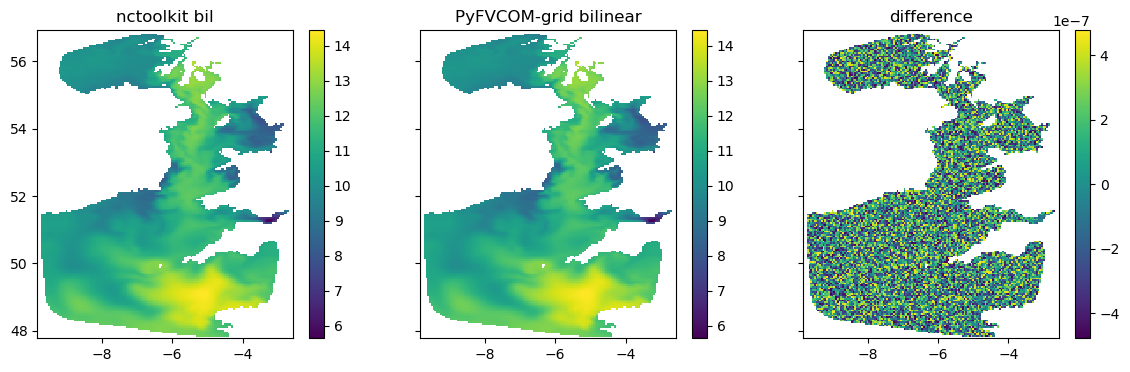

In [12]:
G = dict(lon=[-9.8, -2.6], lat=[47.8, 56.9], res=0.05)
def regrid(method):
    d = top.copy(); d.subset(variables="temp"); d.to_latlon(**G, method=method)
    r = d.to_xarray(); return r.lon.values, r.lat.values, r.temp.values.reshape(NTIME, -1, r.lon.size)

lon, lat, bil = regrid("bil")
lons, lats = np.meshgrid(lon, lat)
bil_ref = np.array([ref.bilinear(x[t], lons, lats) for t in range(NTIME)])
record("to_latlon bil", bil, bil_ref.reshape(bil.shape), 1e-6, "vs matplotlib LinearTriInterpolator on PyFVCOM's triangles")

lon, lat, nn = regrid("nn")
near, ratio = ref.nearest(x[0], lons, lats)
nn0 = nn[0].ravel()
found = np.isfinite(nn0)
differ = found & ~np.isclose(nn0, near.ravel(), atol=1e-6)
print(f"nn: {found.sum()} points, {differ.sum()} differ from the nearest node; those have nearest/second-nearest distance ratios {np.sort(ratio.ravel()[differ]).round(3)} (near ties)")
keep = found & ~differ
record("to_latlon nn (excluding near ties)", nn0[keep], near.ravel()[keep], 1e-6)
record("to_latlon nn (same domain as bil)", np.isfinite(nn0).astype(float), np.isfinite(bil_ref[0]).ravel().astype(float), 0)

fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for a, field, title in zip(ax, [bil[0].reshape(lons.shape), bil_ref[0], (bil[0].reshape(lons.shape) - bil_ref[0])],
                           ["nctoolkit bil", "PyFVCOM-grid bilinear", "difference"]):
    im = a.pcolormesh(lons, lats, field, shading="auto"); a.set_title(title); plt.colorbar(im, ax=a)
plt.show()

In [13]:
d = top.copy(); d.subset(variables="temp"); d.to_transect(start=[-6, 50], end=[-4, 51], nsteps=20)
expected = np.array([ref.bilinear(x[t], np.linspace(-6, -4, 20), np.linspace(50, 51, 20)) for t in range(NTIME)])
record("to_transect", d.to_xarray().temp.values.reshape(NTIME, -1), expected, 1e-6)

OK   to_transect                            abs 4.22e-07  rel 3.50e-08  one-sided missing 0


### `match_points`

Points are the centres of deep-water triangles, one per day.

In [14]:
tri = ref.grid.triangles
deep = np.where(ref.h > 60)[0][::5000][:3]
which = [np.where((tri == n).any(1))[0][0] for n in deep]
plon, plat = ref.lon[tri[which]].mean(1), ref.lat[tri[which]].mean(1)
df = pd.DataFrame({"lon": plon, "lat": plat, "year": 2012, "month": 1, "day": [2, 3, 4]})
got = ds.copy().match_points(df.copy(), variables="temp", top=True, quiet=True).sort_values("day")
record("match_points (surface)", got.temp.values, [ref.bilinear(x[i], plon[i], plat[i]).item() for i in range(3)], 1e-6)

df["depth"] = [5.0, 20.0, 40.0]
got = ds.copy().match_points(df.copy(), variables="temp", quiet=True).sort_values("day")
exp = []
for i in range(3):
    col = [ref.bilinear(ref.values[i, k], plon[i], plat[i]).item() for k in range(24)]
    sig = [ref.bilinear(ref.siglay[k], plon[i], plat[i]).item() for k in range(24)]
    tot = ref.bilinear(ref.h, plon[i], plat[i]).item() + ref.bilinear(ref.zeta[i], plon[i], plat[i]).item()
    exp.append(np.interp(df.depth[i], -np.array(sig) * tot, col))
record("match_points (with depths)", got.temp.values, exp, 1e-4,
       "nctoolkit regrids layer thickness, the reference regrids sigma, so close not identical")

OK   match_points (surface)                 abs 3.18e-07  rel 2.65e-08  one-sided missing 0


OK   match_points (with depths)             abs 6.62e-07  rel 5.51e-08  one-sided missing 0


## Methods that must refuse FVCOM data

In [15]:
refused = {
 "zonal_mean": lambda d: d.zonal_mean(), "zonal_max": lambda d: d.zonal_max(),
 "meridonial_mean": lambda d: d.meridonial_mean(), "box_mean": lambda d: d.box_mean(),
 "resample_grid": lambda d: d.resample_grid(1), "distribute": lambda d: d.distribute(2, 2),
 "invert('latitudes')": lambda d: d.invert("latitudes"), "strip_variables": lambda d: d.strip_variables(),
 "set_gridtype": lambda d: d.set_gridtype("lonlat"), "generate_level_bounds": lambda d: d.generate_level_bounds(),
 "fix_amm7_grid": lambda d: d.fix_amm7_grid(), "fix_nemo_ersem_grid": lambda d: d.fix_nemo_ersem_grid(),
 "crop(nco=True)": lambda d: d.crop(**box, nco=True), "vertical_interp(fixed=True)": lambda d: d.vertical_interp([5], fixed=True),
}
for name, call in refused.items():
    try:
        call(ds.copy()); status = "NO ERROR"
    except (TypeError, ValueError) as e:
        status = "refused: " + str(e)[:70]
    results.append(dict(method=name, max_abs_diff=np.nan, max_rel_diff=np.nan, missing_in_one_only=0, tolerance=np.nan,
                        agrees=status.startswith("refused"), note=status))
    print(f"{name:30s} {status}")

zonal_mean                     refused: zonal_mean: This method does not work with FVCOM data, as it needs a r
zonal_max                      refused: zonal_max: This method does not work with FVCOM data, as it needs a re
meridonial_mean                refused: meridonial_mean: This method does not work with FVCOM data, as it need
box_mean                       refused: box_mean: This method does not work with FVCOM data, as it needs a reg
resample_grid                  refused: resample_grid: This method does not work with FVCOM data, as it needs 
distribute                     refused: distribute: This method does not work with FVCOM data, as it splits re
invert('latitudes')            refused: invert: Inverting latitudes does not work with FVCOM data, as the mesh
strip_variables                refused: strip_variables: This method does not work with FVCOM data, as it remo
set_gridtype                   refused: set_gridtype: This method does not work with FVCOM data, as the FVCOM 
g

## Summary

In [16]:
summary = pd.DataFrame(results)
pd.set_option("display.width", 200, "display.max_colwidth", 70, "display.max_rows", 200)
print(f"{summary.agrees.sum()} of {len(summary)} checks agree")
summary.style.format({"max_abs_diff": "{:.2e}", "max_rel_diff": "{:.2e}", "tolerance": "{:.0e}"}).apply(
    lambda c: ["background-color: #f8c4c4" if not v else "" for v in c], subset=["agrees"])

53 of 53 checks agree


,method,max_abs_diff,max_rel_diff,missing_in_one_only,tolerance,agrees,note
0,layer_thickness (nodes),4.77e-07,3.40e-08,0,1e-06,True,
1,layer_thickness (elements),4.77e-07,3.64e-08,0,1e-06,True,
2,vertical_mean,4.85e-07,3.36e-08,0,1e-06,True,
3,vertical_mean (elements),5.67e-08,4.97e-08,0,1e-06,True,
4,vertical_integration,1.70e-04,6.25e-08,0,1e-06,True,
5,"vertical_mean(depth_range=[0,20])",2.02e-06,1.40e-07,0,1e-06,True,layers partly inside the range are weighted by the overlap
6,"vertical_integration(depth_range=[0,20])",3.43e-05,1.19e-07,0,1e-06,True,
7,top,0.00e+00,0.00e+00,0,1e-06,True,
8,bottom,0.00e+00,0.00e+00,0,1e-06,True,
9,vertical_min,0.00e+00,0.00e+00,0,1e-06,True,not thickness weighted


## Findings

* The vertical grid (thickness, weighted means and integrals, `depth_range`, `top`/`bottom`, masks, interpolation to depths) agrees with PyFVCOM to float32 precision.
* Horizontal methods agree with PyFVCOM's grid too. `spatial_mean` and friends differ by about 0.01% from using FVCOM's projected `art1` areas, because nctoolkit's areas are on the sphere (up to 1% smaller per cell).
* Bilinear regridding, transects and `match_points` agree with linear interpolation in the mesh's triangles. Nearest-neighbour regridding picks the second-nearest node at a handful of near-tie points, since CDO measures distance slightly differently.
* The methods documented as unsupported raise a clear error.
* No bugs found in nctoolkit.